# 02 · Model comparison

Rolling-origin backtests: each year Y is forecast by models trained only on data up to December of Y-1. Metrics cover 2015-2025; 2026 is the untouched holdout. MAE is in KES/kg (pooled) and in percent (log errors). MASE scales errors by each series' in-sample seasonal-naive error.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
PROC, STORE, FIG = ROOT / "data/processed", ROOT / "data/store", ROOT / "reports/figures"
FIG.mkdir(parents=True, exist_ok=True)
PHASE_COLORS = {"Normal": "#2e7d32", "Stress": "#f2b705", "Alert": "#e8590c", "Crisis": "#c92a2a"}
DROUGHTS = [("2010-10-01", "2011-09-01"), ("2016-10-01", "2017-08-01"), ("2021-10-01", "2023-03-01")]
def shade(ax):
    for a, b in DROUGHTS:
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color="#c92a2a", alpha=0.07, lw=0)
metrics = json.loads((STORE / "metrics.json").read_text())


## All models, on rows where every model has a forecast

SARIMAX and Prophet need at least 24 months of training data, so this comparison uses the longer series.

In [2]:
pc = pd.DataFrame(metrics["point_common"])
pc.pivot_table(index="model", columns="h", values=["rel_mae_naive", "mae_pct", "mase"]).round(3)

mae_pct                   mase               rel_mae_naive              
h                 1       2       3      1      2      3             1      2      3
model                                                                               
lgbm          5.967   8.176  10.027  0.332  0.468  0.599         0.975  0.974  0.977
lgbm_smooth   5.960   8.180   9.969  0.332  0.470  0.595         0.971  0.976  0.977
naive         6.232   8.725  10.845  0.345  0.499  0.635         1.000  1.000  1.000
prophet       9.083  12.914  16.355  0.489  0.696  0.884         1.611  1.611  1.605
sarimax       6.511   8.789  10.839  0.359  0.498  0.629         1.034  1.002  1.001
smooth        6.711   9.182  11.100  0.376  0.526  0.649         1.046  1.039  1.006
snaive       18.538  18.652  18.439  1.029  1.050  1.060         2.803  2.115  1.682
sokoradar     6.037   8.207  10.015  0.334  0.468  0.587         0.974  0.959  0.951
xgb           5.905   8.184   9.920  0.329  0.469  0.593         0.967  0.972  0.973

## Gradient boosting and ensemble on every backtest forecast

In [3]:
pt = pd.DataFrame(metrics["point"])
tab = pt.pivot_table(index="model", columns="h", values=["rel_mae_naive", "mae_kes", "mae_pct", "mase"]).round(3)
tab

mae_kes                 mae_pct                   mase               rel_mae_naive              
h                 1       2       3       1       2       3      1      2      3             1      2      3
model                                                                                                       
lgbm          6.678   8.092   9.903   6.772   8.566  10.323  0.388  0.504  0.620         0.990  0.997  1.023
lgbm_smooth   6.543   8.136   9.763   6.687   8.533  10.173  0.383  0.501  0.610         0.970  1.003  1.009
naive         6.748   8.115   9.679   6.923   8.928  10.717  0.395  0.524  0.632         1.000  1.000  1.000
smooth        6.593   8.078   9.644   7.047   9.038  10.803  0.405  0.531  0.637         0.977  0.995  0.996
snaive       14.121  14.499  15.192  16.426  16.791  17.204  0.941  0.972  1.001         2.093  1.787  1.570
sokoradar     6.550   7.927   9.500   6.722   8.510  10.146  0.384  0.498  0.602         0.971  0.977  0.982
xgb           6.681   8.142   9.783   6.744   8.588  10.166  0.387  0.505  0.611         0.990  1.003  1.011

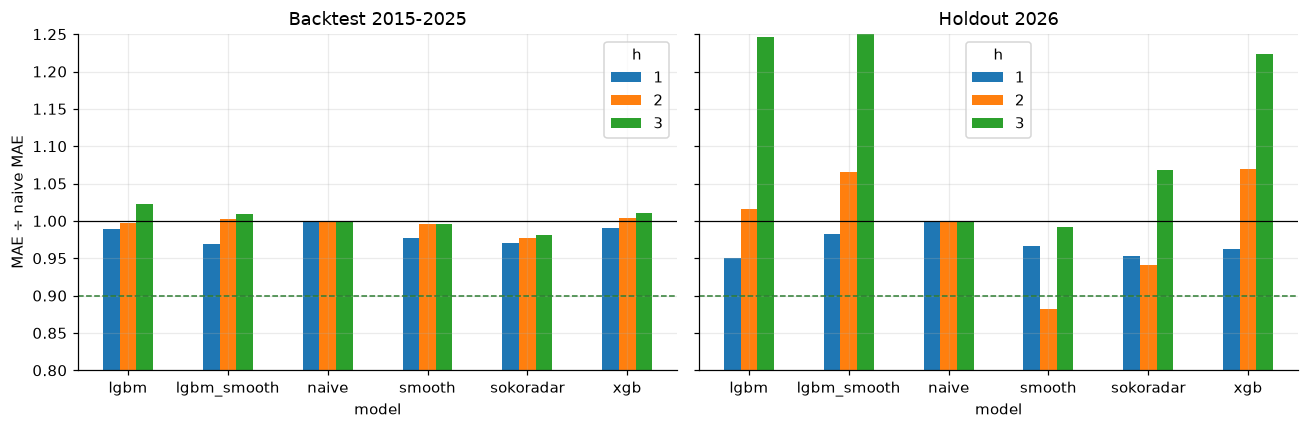

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (name, key) in zip(axes, [("Backtest 2015-2025", "point"), ("Holdout 2026", "point_holdout")]):
    d = pd.DataFrame(metrics[key]); d = d[d.model != "snaive"]
    piv = d.pivot(index="model", columns="h", values="rel_mae_naive")
    piv.plot.bar(ax=ax, rot=0); ax.axhline(1, color="k", lw=0.8); ax.axhline(0.9, color="#2e7d32", ls="--", lw=1)
    ax.set_title(name); ax.set_ylabel("MAE ÷ naive MAE"); ax.set_ylim(0.8, 1.25)
fig.tight_layout(); fig.savefig(FIG / "model_comparison.png", bbox_inches="tight")

### Seasonal naive

The seasonal-naive forecast (same month last year) is far worse than every model (MASE near 1 against about 0.35-0.6), so SokoRadar clears the first bar comfortably. The hard bar is the naive last-month price: staple prices behave close to a random walk month to month.

model   lgbm               sokoradar              
h          1      2      3         1      2      3
fold                                              
2009   1.162  1.200  1.445     1.111  1.106  1.204
2010   1.039  1.091  1.073     1.045  1.012  1.001
2011   0.962  0.939  0.938     0.984  0.957  0.938
2012   0.992  0.943  0.882     0.963  0.912  0.892
2013   0.980  0.948  0.937     0.965  0.917  0.891
2014   0.993  1.037  1.197     0.949  0.929  0.982
2015   0.943  0.939  1.027     0.926  0.882  0.885
2016   0.978  0.955  0.932     0.982  0.927  0.907
2017   0.923  0.828  0.814     0.940  0.869  0.851
2018   1.020  1.021  1.087     1.089  1.049  1.095
2019   0.976  0.927  0.900     0.973  0.937  0.914
2020   0.992  0.967  0.880     0.997  0.971  0.922
2021   1.044  1.070  1.184     0.985  1.019  1.033
2022   1.003  0.890  0.868     0.967  0.919  0.908
2023   0.992  1.013  1.002     0.972  0.995  0.980
2024   0.994  1.029  1.118     0.968  1.000  1.049
2025   0.970  1.031  1.035     0.947  0.984  0.990
2026   0.951  1.016  1.247     0.953  0.941  1.068

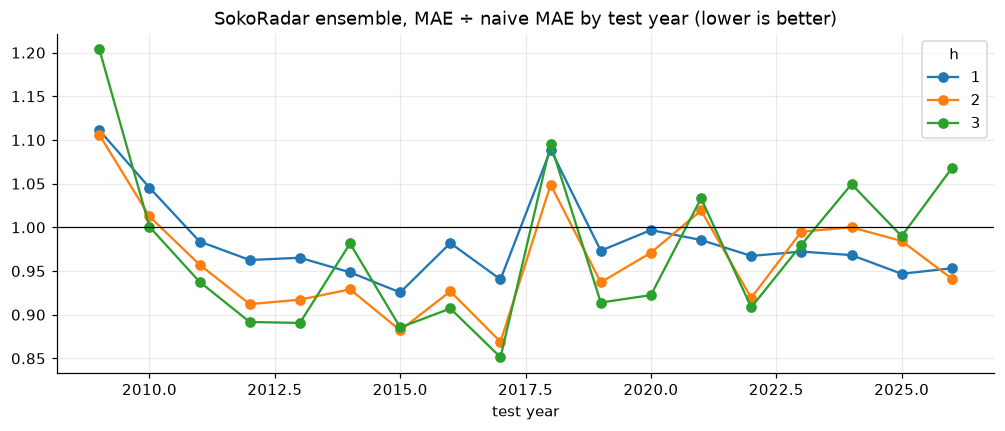

In [5]:
by_year = pd.read_parquet(STORE / "metrics_by_year.parquet")
piv = by_year[by_year.model.isin(["sokoradar", "lgbm"])].pivot_table(index="fold", columns=["model", "h"],
                                                                    values="rel_mae_naive")
ax = piv["sokoradar"].plot(figsize=(11, 4), marker="o"); ax.axhline(1, color="k", lw=0.8)
ax.set_title("SokoRadar ensemble, MAE ÷ naive MAE by test year (lower is better)"); ax.set_xlabel("test year")
plt.savefig(FIG / "accuracy_by_year.png", bbox_inches="tight"); piv.round(3)

Gains are largest in shock years (2011-13, 2017, 2022), when momentum and seasonal reversals matter. The ensemble loses in 2018, when prices collapsed after the 2017 crisis and imports, and at 2-3 months in 2021, the first year of the refugee-camp series, which the models had never seen.

In [6]:
seg = pd.read_parquet(STORE / "metrics_by_segment.parquet")
seg.pivot_table(index=["pricetype", "commodity"], columns=["model", "h"], values="rel_mae_naive").round(3)

model                   lgbm               naive           sokoradar              
h                          1      2      3     1    2    3         1      2      3
pricetype commodity                                                               
Retail    beans        0.983  0.989  1.028   1.0  1.0  1.0     0.967  0.973  0.991
          goat_meat    1.014  1.101  1.154   1.0  1.0  1.0     0.973  1.049  1.063
          maize        0.985  0.964  0.962   1.0  1.0  1.0     0.977  0.951  0.946
          maize_flour  1.003  1.039  1.095   1.0  1.0  1.0     0.974  1.000  1.019
Wholesale beans        0.952  0.909  0.938   1.0  1.0  1.0     0.951  0.903  0.893
          maize        0.951  0.893  0.862   1.0  1.0  1.0     0.970  0.926  0.895

## Research question 2: do satellite rainfall and vegetation help?

LightGBM backtests with nested feature sets (2015-2025).

h,1,2,3
feature_set,,,
price_only,1.000,1.039,1.078
price_network,0.987,1.025,1.056
price_climate,1.000,1.024,1.034
sokoradar,0.990,0.997,1.023
full,1.003,1.041,1.074


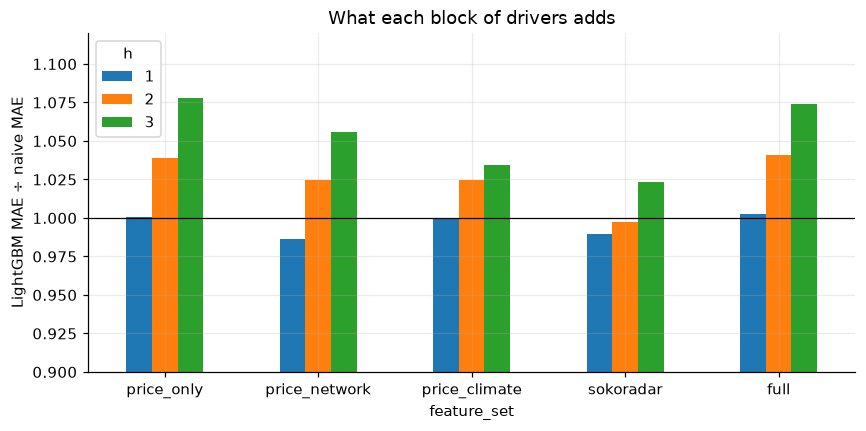

In [7]:
ab = pd.DataFrame(metrics["ablation"])
order = ["price_only", "price_network", "price_climate", "sokoradar", "full"]
piv = ab.pivot(index="feature_set", columns="h", values="rel_mae_naive").reindex(order)
ax = piv.plot.bar(figsize=(9, 4), rot=0); ax.axhline(1, color="k", lw=0.8); ax.set_ylim(0.9, 1.12)
ax.set_ylabel("LightGBM MAE ÷ naive MAE"); ax.set_title("What each block of drivers adds")
plt.savefig(FIG / "ablation.png", bbox_inches="tight"); piv.round(3)

## Ensemble weights used for live forecasts

In [8]:
w = pd.read_parquet(STORE / "ensemble_weights.parquet")
w.pivot_table(index=["commodity", "pricetype", "h"], columns="model", values="weight").round(2)

model                    lgbm  lgbm_smooth  naive  prophet  sarimax  smooth   xgb
commodity   pricetype h                                                          
beans       Retail    1  0.15         0.16   0.14     0.08     0.14    0.17  0.16
                      2  0.15         0.16   0.15     0.06     0.15    0.17  0.16
                      3  0.15         0.15   0.16     0.06     0.16    0.17  0.15
goat_meat   Retail    1  0.15         0.16   0.15     0.03     0.18    0.18  0.14
                      2  0.15         0.14   0.18      NaN     0.20    0.19  0.14
                      3  0.14         0.14   0.20      NaN     0.19    0.21  0.13
maize       Retail    1  0.15         0.16   0.14     0.09     0.15    0.16  0.15
                      2  0.16         0.16   0.14     0.07     0.15    0.16  0.16
                      3  0.16         0.17   0.15     0.06     0.13    0.16  0.17
            Wholesale 1  0.19         0.18   0.18     0.03     0.11    0.13  0.18
                      2  0.19         0.20   0.16     0.01     0.13    0.12  0.19
                      3  0.22         0.20   0.14      NaN     0.11    0.12  0.21
maize_flour Retail    1  0.16         0.17   0.16     0.04     0.14    0.16  0.16
                      2  0.17         0.16   0.16     0.03     0.15    0.16  0.17
                      3  0.16         0.17   0.17     0.02     0.15    0.17  0.16

## What the global model relies on

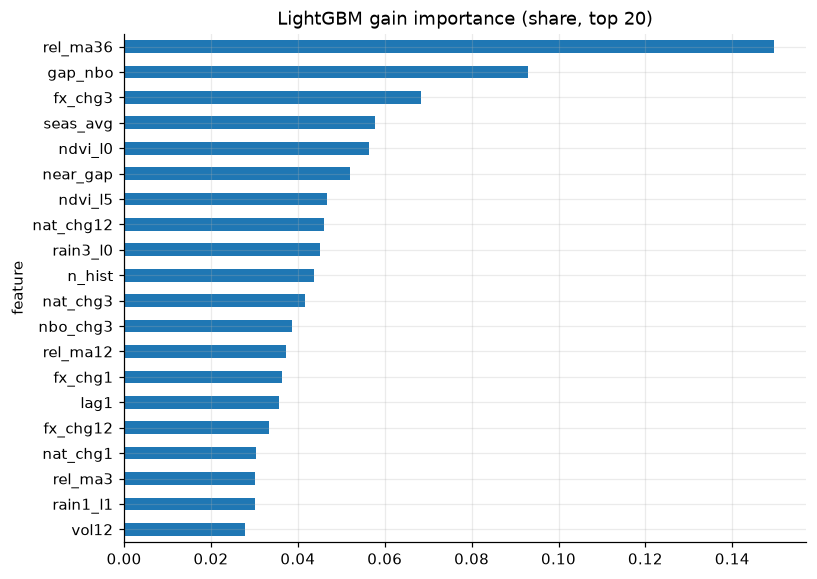

In [9]:
imp = pd.read_parquet(STORE / "feature_importance.parquet")
top = imp.groupby("feature").gain.mean().sort_values().tail(20)
ax = (top / top.sum()).plot.barh(figsize=(8, 6)); ax.set_title("LightGBM gain importance (share, top 20)")
plt.savefig(FIG / "importance.png", bbox_inches="tight")

## Uncertainty: 80% conformal intervals

In [10]:
pd.DataFrame(metrics["intervals"]).round(3)

,h,n,coverage,raw_quantile_coverage,median_width_pct
0,1,3219,0.786,0.723,21.912
1,2,3111,0.789,0.717,30.253
2,3,3072,0.781,0.720,38.401


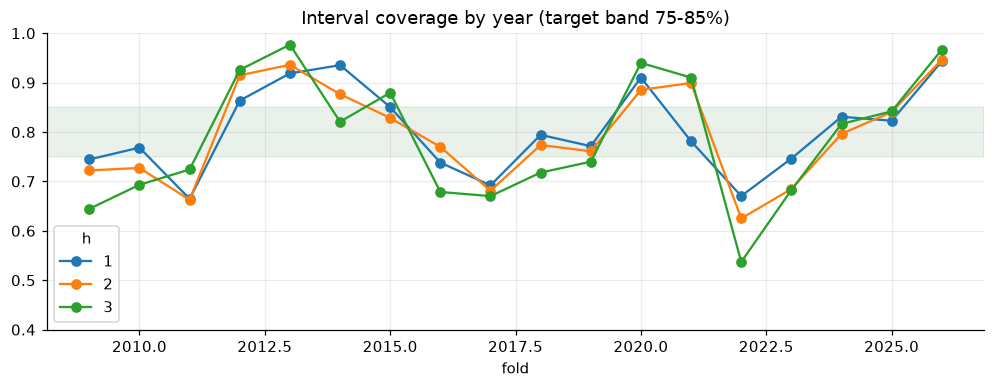

In [11]:
bt = pd.read_parquet(STORE / "backtest.parquet")
bt = bt[bt.y_true.notna() & bt.lo.notna()]
bt["inside"] = (bt.y_true >= bt.lo) & (bt.y_true <= bt.hi)
cov = bt.groupby(["fold", "h"]).inside.mean().unstack()
ax = cov.plot(figsize=(11, 3.5), marker="o"); ax.axhspan(0.75, 0.85, color="#2e7d32", alpha=0.1)
ax.set_title("Interval coverage by year (target band 75-85%)"); ax.set_ylim(0.4, 1)
plt.savefig(FIG / "coverage_by_year.png", bbox_inches="tight")

## Research question 1: how far ahead, how accurately?

Typical absolute error grows from about 7% at one month to about 10-11% at three months, and 80% intervals widen from about ±11% to ±20%. Against the naive forecast the ensemble's edge is a few percent, largest in drought years and wholesale markets.